# Sparse-sensor tennis forehand inference: first experiment

**Question.** We have only timestamped racket-mounted accelerometer, gyroscope and orientation readings, with no body landmarks.
Can we (a) segment a forehand into phases and (b) estimate one body variable, trunk/shoulder-line rotation?

**Data.** No public dataset pairs racket IMU streams with body kinematics and phase labels. This first experiment therefore runs on a
**physics-based simulator** with known ground truth (`src/simulate.py`), with 12 players × 2 sessions × 30 forehands.
The simulator models a kinematic chain (trunk → shoulder → arm → wrist → racket), a butt-cap IMU at 200 Hz with ±16 g / ±2000 dps
range, impact shock, sensor noise and bias, AHRS heading drift, timestamp jitter and bursty BLE packet loss.
Every number below therefore checks the *method* and the *physics argument*. It is not an accuracy claim for real players.

The full leave-one-player-out run is `run_all.py` (about 8 min on a laptop CPU). This notebook loads its outputs and re-runs the cheap parts live.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import numpy as np
from IPython.display import Image, display, Markdown
from simulate import sample_player, simulate_session, corrupt, PHASES, FS
from features import session_features
import nonident
S = json.load(open('../results/summary.json'))

## 1. Feature representation and a simple baseline

**Representation.** Absolute heading is not trustworthy: the 6-axis AHRS has an unknown, drifting yaw. Every feature is therefore
heading-free:

* gyro magnitude and body-axis components; **yaw rate about gravity** (gyro rotated to the world frame using only the tilt part of the orientation)
* accel magnitude and components (clipped at ±16 g, with a saturation flag); gravity-removed linear-acceleration magnitude and its vertical component
* **tip elevation** and **face tilt** relative to gravity (from the orientation's roll/pitch, which gravity keeps observable)
* jerk (sample-to-sample accel change), which picks out the impact transient
* multi-scale centred windows (25 / 105 / 305 ms) of mean and std, past-vs-future 150 ms means, and Δyaw over the past and next 300 ms
* 100 Hz frames (hop of 2 samples), 60 features per frame

**Baseline.** A frame-wise multinomial logistic regression. A gradient-boosted tree classifier is a stronger frame-wise reference.
Neither model knows anything about phase order.

received samples: 90.8%   frames: 1331   features: 60
peak |gyro| 1150 dps, peak |accel| 21.1 g (clipped), peak head speed 17.7 m/s


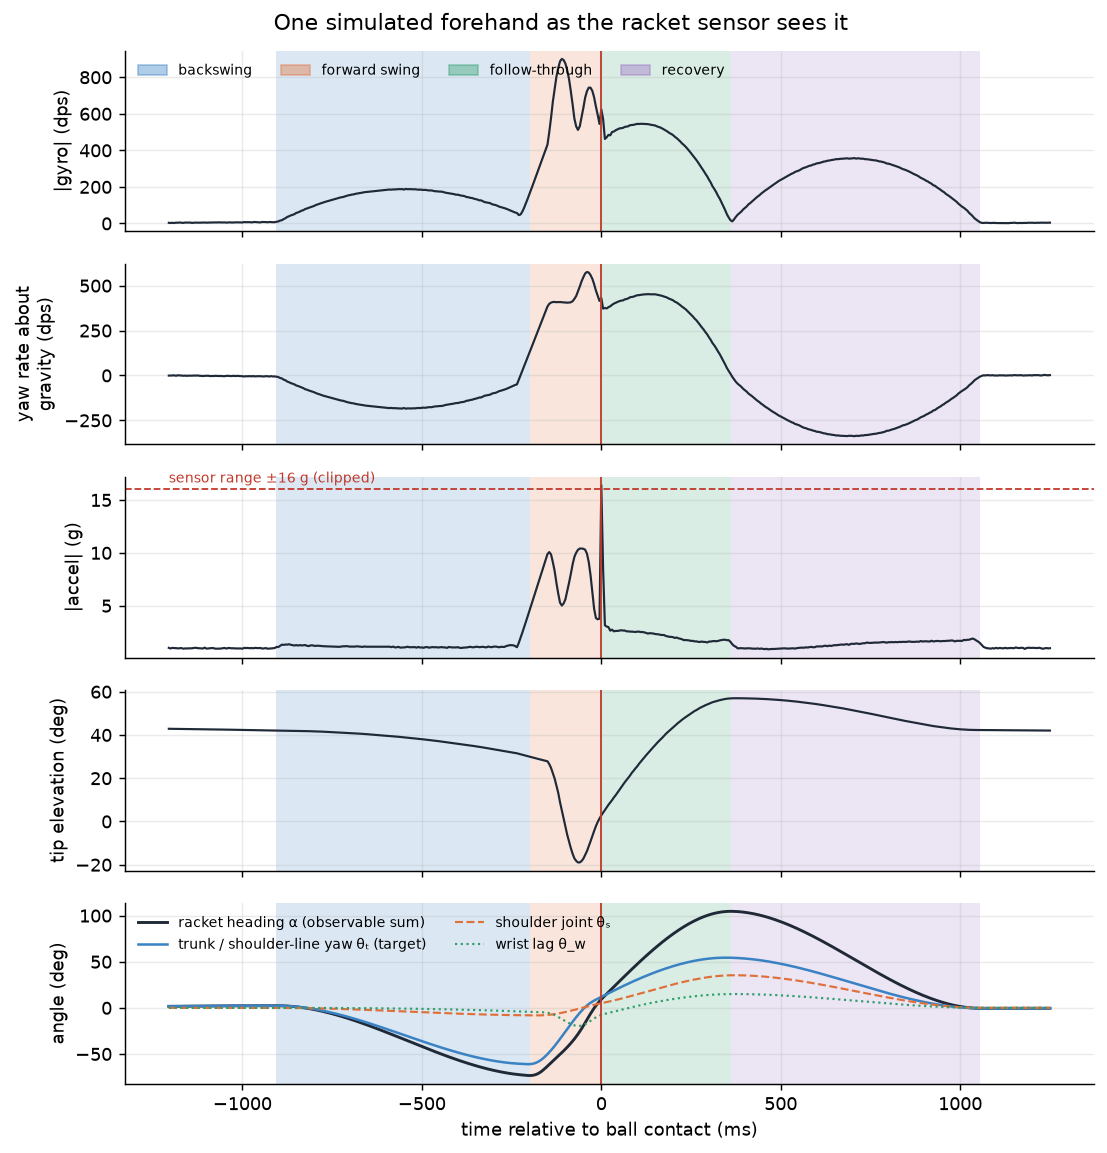

In [2]:
rng = np.random.default_rng(11)
p = sample_player(0, np.random.default_rng(7))
clean = simulate_session(p, 3, rng, distract=False)
stream = corrupt(clean, np.random.default_rng(1), 0.04)
f = session_features(stream, len(clean['t']))
print('received samples: %.1f%%   frames: %d   features: %d' % (100*stream['received_frac'], *f['X'].shape))
print('peak |gyro| %.0f dps, peak |accel| %.1f g (clipped), peak head speed %.1f m/s' % (
    f['ch']['gyr_mag'].max(), f['ch']['acc_mag'].max(), clean['head_speed'].max()))
display(Image('../figures/signals.png', width=760))

## 2. Temporal model: a duration-constrained left-to-right HMM over classifier posteriors

**Why this model first.**
* A forehand has a **fixed grammar**: idle → backswing → forward swing → follow-through → recovery → idle. A frame classifier ignores it and flickers.
  The HMM cannot produce illegal orders (for example, follow-through before forward swing) and produces exactly one contact per stroke.
* Each phase is a chain of *n_k* states, *n_k* = 0.6 × the 5th-percentile training duration. This gives a hard **minimum duration**, and a forward swing cannot last 20 ms.
  The last state's self-loop matches the mean duration.
* Emissions are **scaled likelihoods** p(k|x)/p(k) from whichever frame classifier is used, the hybrid trick from speech recognition.
  The comparison therefore isolates exactly what temporal structure adds.
* **Missing data** gets a principled treatment: frames inside long gaps get a flat emission, and Viterbi bridges them using the grammar and the durations.
* Data-cheap and interpretable: only about 15 parameters are learned (durations and priors). A BiGRU or TCN is the next step once real labelled data exist.

Contact time is the decoded forward-swing → follow-through boundary, snapped to the impact onset (the first sample within ±40 ms whose jerk exceeds half the local peak).

| model | frame macro-F1 (± sd over players) | edit score | F1@50 | contact P / R | contact MAE (ms) | reversal MAE (ms) | onset MAE (ms) |
|---|---|---|---|---|---|---|---|
| LR | 98.3 ± 0.5 | 93.8 | 97.6 | 99.4 / 99.4 | 6.1 | 6 | 10 |
| HGB | 98.5 ± 0.7 | 96.0 | 97.2 | 98.2 / 99.6 | 6.0 | 5 | 6 |
| LR+HMM | 98.4 ± 0.5 | 100.0 | 99.8 | 97.9 / 97.9 | 5.7 | 6 | 8 |
| HGB+HMM | 98.4 ± 0.5 | 100.0 | 99.8 | 98.1 / 98.1 | 5.5 | 6 | 6 |

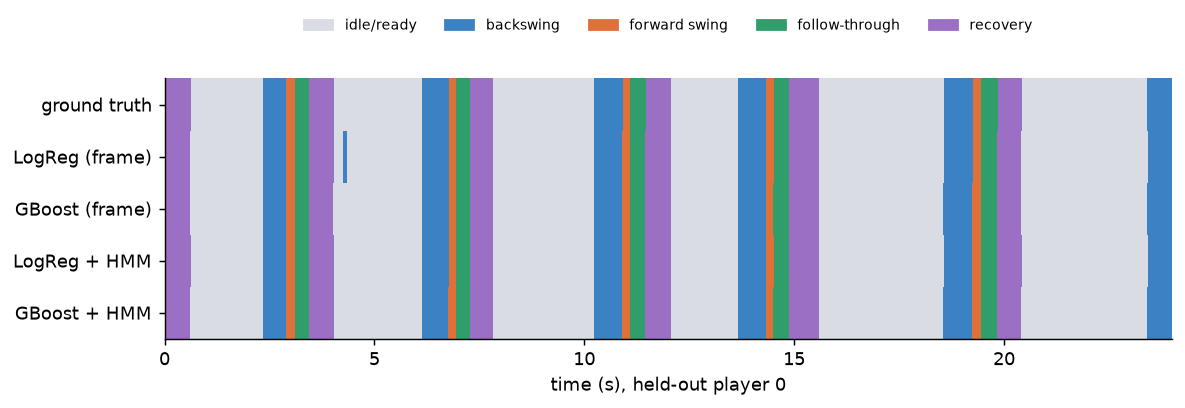

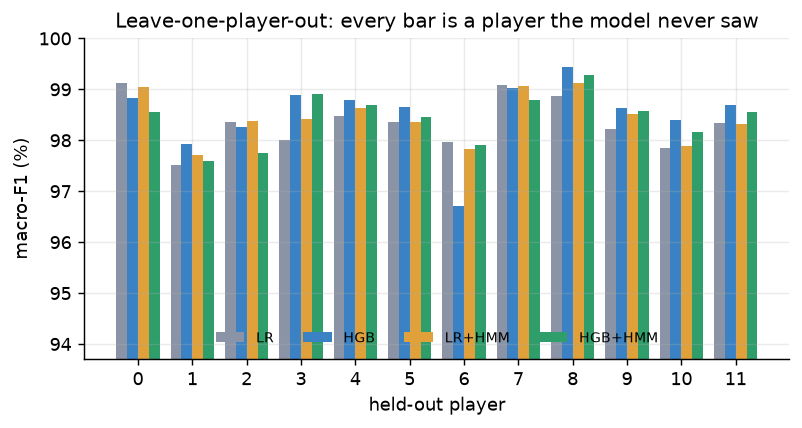

In [3]:
rows = []
for m in ['LR', 'HGB', 'LR+HMM', 'HGB+HMM']:
    r = S['phase'][m]
    rows.append(f"| {m} | {r['macro_f1']:.1f} ± {r['macro_f1_sd_players']:.1f} | {r['edit']:.1f} | {r['f1_50']:.1f} | "
                f"{r['contact_p']:.1f} / {r['contact_r']:.1f} | {r['contact_mae_ms']:.1f} | {r['b_reversal_mae_ms']:.0f} | {r['b_onset_mae_ms']:.0f} |")
display(Markdown('| model | frame macro-F1 (± sd over players) | edit score | F1@50 | contact P / R | contact MAE (ms) | reversal MAE (ms) | onset MAE (ms) |\n'
                 '|---|---|---|---|---|---|---|---|\n' + '\n'.join(rows)))
display(Image('../figures/timeline.png', width=820))
display(Image('../figures/per_player.png', width=640))

## 3. Missing and noisy data

| issue | where it comes from | handling |
|---|---|---|
| bursty packet loss | BLE, 4 samples/packet, Gilbert–Elliott bursts, plus occasional 150–400 ms dropouts | re-grid on timestamps, interpolate gaps ≤ 50 ms (quaternion nlerp with sign continuity), **mask** longer gaps; the HMM gives masked frames a flat emission |
| timestamp jitter and clock skew | device clock | resample on timestamps, never on sample count |
| saturation | butt-cap centripetal and impact loads exceed ±16 g | saturation flag as a feature; never use clipped accel for integration or radius estimates |
| heading drift | 6-axis AHRS has no magnetometer | use only gravity-referenced quantities and yaw *rates*; integrate yaw only within one stroke (about 1.5 s) |
| dynamic tilt error | AHRS accel correction is corrupted during the swing | prefer gyro-derived features during high dynamics; tilt-derived features carry the error |
| distractors | racket twirls, ball bouncing, aborted half-swings | labelled idle in training; the HMM's minimum durations reject short bursts |

The ablation below re-corrupts each held-out player's sessions at increasing loss rates and compares naive zero-filling with interpolate-and-mask.

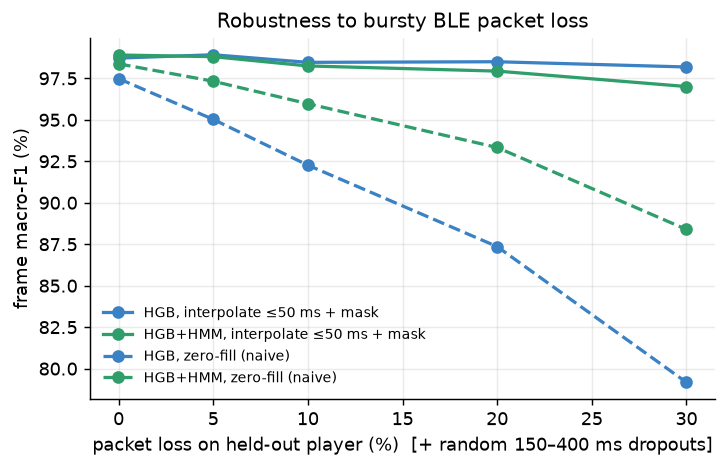

0.05_interp   HGB 98.9   HGB+HMM 98.8
0.05_zero     HGB 95.0   HGB+HMM 97.3
0.0_interp    HGB 98.7   HGB+HMM 98.9
0.0_zero      HGB 97.5   HGB+HMM 98.4
0.1_interp    HGB 98.5   HGB+HMM 98.2
0.1_zero      HGB 92.3   HGB+HMM 96.0
0.2_interp    HGB 98.5   HGB+HMM 97.9
0.2_zero      HGB 87.4   HGB+HMM 93.3
0.3_interp    HGB 98.2   HGB+HMM 97.0
0.3_zero      HGB 79.2   HGB+HMM 88.4


In [4]:
display(Image('../figures/robustness.png', width=560))
rob = S['robustness']
for k in sorted(rob):
    print(f"{k:12s}  HGB {rob[k]['HGB']:.1f}   HGB+HMM {rob[k]['HGB+HMM']:.1f}")

## 4. Player-held-out validation and metrics

* **Leave-one-player-out** (12 folds). Both sessions of the test player are held out, so no stroke, session offset or style of that player reaches training.
  Random frame splits would leak (adjacent frames are nearly identical), and so would stroke-level splits (player style is shared across strokes).
* Report the **mean and the spread across players**. With 12 players the spread across players is the honest uncertainty, not the spread across frames.
* Metrics:
  * frame macro-F1 (phases are imbalanced; the forward swing is about 5% of frames)
  * **edit score** and **F1@IoU 0.5** (segment-level: penalise flicker and over-segmentation)
  * **contact detection** precision/recall within ±50 ms, and the timing error in ms
  * **boundary MAE** for each transition (onset, racket reversal, contact, end of follow-through, end of recovery)
  * rotation: RMSE in degrees, **peak-coil error** per stroke (the coaching-relevant number), Pearson r
* Hyper-parameters (HMM min-duration factor, window sizes) were fixed before the run. Tuning them should use a nested split inside the training players.

## 5. Body-motion variable: trunk (shoulder-line) rotation, and what is not identifiable

**Target.** Trunk yaw change since backswing onset, θₜ(t) − θₜ(onset). The onset is detected, not given, so this test is end-to-end.

**Estimators** (trained on 11 players, tested on the 12th):
1. *Proxy*: θ̂ = k · ψ, where ψ is the racket's integrated yaw about gravity and k is the average trunk share, fitted on the training players.
2. *Regressor*: gradient-boosted trees on ψ, its running min and max, elevation, face tilt, |ω|, linear accel, the centripetal radius proxy |a|/ω², and phase.
3. *Perfect-sensor control*: the same regressor fed the **exact** noise-free racket pose and forces. If this is no better than (2), sensor noise is not the problem; the observation model is.

k x racket yaw                       RMSE  13.8 deg   peak-coil MAE  17.7 deg   r 0.950
GBoost regressor                     RMSE   7.1 deg   peak-coil MAE   7.2 deg   r 0.991
regressor, PERFECT sensor            RMSE   6.6 deg   peak-coil MAE   7.8 deg   r 0.994
proxy + 5 calibration strokes        RMSE  12.6 deg   peak-coil MAE  14.6 deg   r 0.950
regressor + 5 calibration strokes    RMSE   5.3 deg   peak-coil MAE   4.7 deg   r 0.991
proxy slope k fitted per fold (one number for everyone): [0.49 0.5  0.51 0.49 0.5  0.5  0.5  0.49 0.51 0.49 0.5  0.5 ]


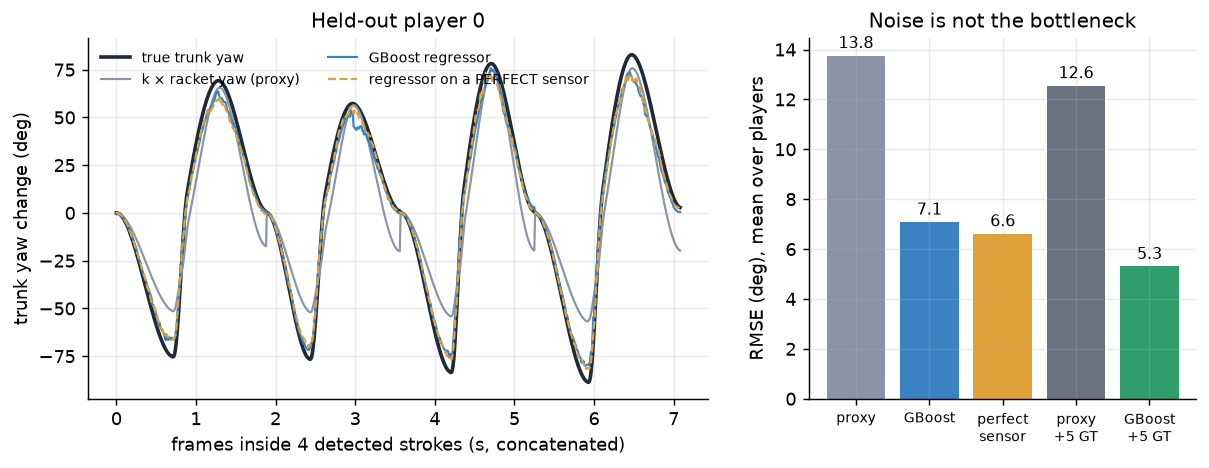

In [5]:
R = S['rotation']
for m, name in [('proxy','k x racket yaw'), ('hgb','GBoost regressor'), ('oracle','regressor, PERFECT sensor'),
                ('proxy_cal5','proxy + 5 calibration strokes'), ('hgb_cal5','regressor + 5 calibration strokes')]:
    print(f"{name:36s} RMSE {R[m]['rmse']:5.1f} deg   peak-coil MAE {R[m]['peak_coil_mae']:5.1f} deg   r {R[m]['r']:.3f}")
print('proxy slope k fitted per fold (one number for everyone):', np.round(R['k_share'], 2))
display(Image('../figures/rotation.png', width=860))

**Constructive non-identifiability.** Take one forehand and move 40% of the trunk rotation into the shoulder joint.
Racket heading is the sum of the joint angles, so the racket's orientation, and hence the gyro, are **bit-identical**.
Only the linear acceleration changes, through the lever arm. That change is no larger than the change from an arm 6 cm longer, a nuisance
the model does not know either. So there is no information that separates *more trunk* from *a different body*.

peak trunk coil A -52.6 deg vs B -31.6 deg
max gyro difference 2.1e-11 dps (identical)
rms accel difference: trunk split 0.32 g, arm +6 cm 0.33 g, noise floor 0.04 g


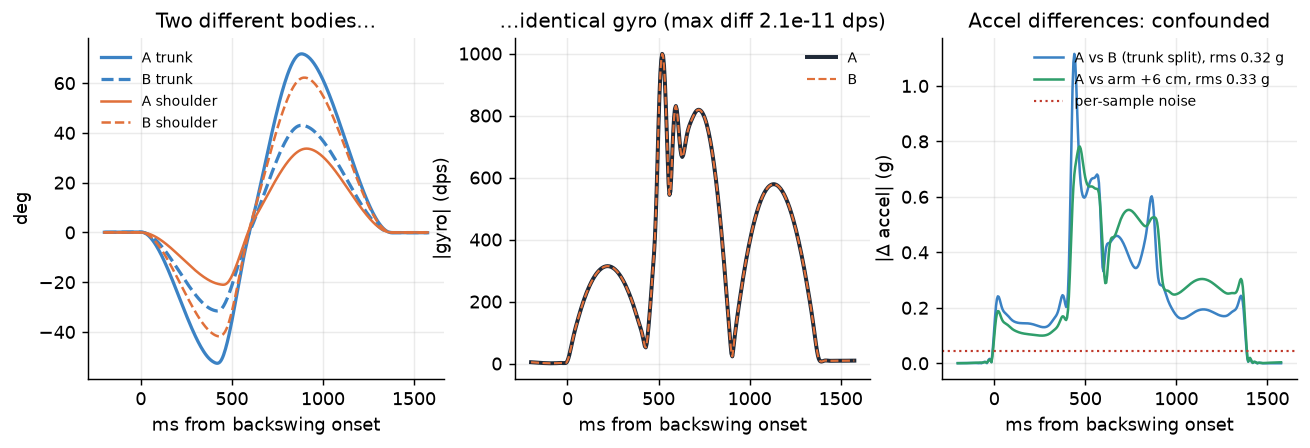

In [6]:
ni = nonident.run()
print(f"peak trunk coil A {ni['peak_trunk_A']:.1f} deg vs B {ni['peak_trunk_B']:.1f} deg")
print(f"max gyro difference {ni['gyr_max_diff_dps']:.1e} dps (identical)")
print(f"rms accel difference: trunk split {ni['dAB_rms']:.2f} g, arm +6 cm {ni['dAL_rms']:.2f} g, noise floor {ni['noise_g']:.2f} g")
display(Image('../figures/nonident.png', width=900))

### Identifiability ledger

| quantity | status from a racket IMU alone | why |
|---|---|---|
| racket angular velocity, swing tempo, phase timing, contact time | **identifiable** | measured directly; impact is a sharp transient |
| racket elevation and face tilt vs gravity | **identifiable** | gravity is a fixed reference (degraded during high-g, by the AHRS) |
| racket head speed | approximately | ω × lever, where the lever is known racket geometry; the sensor's own translational velocity needs integration |
| heading relative to the court | **not identifiable** | no magnetometer; indoors even a magnetometer is distorted. Only relative yaw within a stroke |
| racket position and path in space | not identifiable beyond about 0.5 s | double integration drifts quadratically; no reliable zero-velocity instant |
| **split of racket rotation into trunk / shoulder / elbow / forearm / wrist** | **not identifiable** | 3-DoF orientation vs ≥ 10 body DoF; see the construction above |
| pelvis vs thorax (X-factor), stance, footwork, knee bend, weight transfer | not identifiable | no sensor on the lower body; decoupled from the racket |
| grip type vs sensor mounting offset vs forearm pronation | confounded | all appear as a constant roll offset |
| contact point relative to the body, ball speed and spin, outcome | not identifiable | no ball observation; vibration only hints at the impact location on the strings |
| trunk rotation **for a calibrated player** | partially | with a few labelled strokes the player's trunk share is learned; within-player variation in the share is still invisible |

## 6. Ground truth and extra sensors that resolve the ambiguity

* **Ground truth for training and evaluation:** optical motion capture (Vicon/Qualisys, 200+ Hz, thorax and pelvis marker clusters), hardware-synchronised with the racket IMU.
  Phase boundaries are defined **kinematically** from mocap (onset = trunk yaw velocity threshold, reversal = racket heading minimum, contact = impact transient),
  not by annotators. A cheaper option: 2–3 synchronised high-speed cameras (≥ 120 fps) with multi-view markerless pose. A single camera with 2-D MediaPipe is ambiguous in depth for trunk rotation, which is exactly the axis needed.
* **Sensors that remove the non-identifiability:** a **thorax IMU** (sternum or between the shoulder blades) measures trunk yaw directly. A **pelvis IMU** adds the X-factor.
  A **wrist or forearm IMU** (a smartwatch is enough) splits shoulder from wrist/forearm. A magnetometer gives court heading outdoors.
  Pressure insoles give weight transfer. Ball tracking gives the contact point.
* **Synchronisation:** align all streams on the impact transient (it is sharp in every sensor) plus a tap at session start.
* **Calibration route without mocap:** 5 strokes with camera ground truth per player let us learn that player's trunk share. The calibrated rows in the table above measure what that buys.

## Limits of this experiment

The results are an upper bound for the method. The simulator's player variation, noise model and phase definitions are plausible, not fitted to real data.
Real strokes vary more (open/closed stance, running forehands, slices), real labels are noisier, and the sim-to-real gap is the first thing to measure once real data exist.